# The standard corrections on SIDM samples

`00_correctionlib_tutorial.ipynb` showed the machinery. This notebook applies each
standard correction to the full SIDM simulation and checks that it does what it should:

1. **Pileup reweighting**: the weights, the simulated profile they act on, and what
   they do to the number of reconstructed vertices.
2. **L1 prefiring**, which in 2018 comes from the muon system only.
3. **Object scale factors** for the lepton-jet constituents: PF-muon ID and electron
   reconstruction (applied by default), and the photon pixel veto (evaluated but not
   applied).
4. **Corrections that are already in NanoAODv9** and must not be applied twice: jet
   energy corrections and the electron and photon energy scale and smearing.

Whether these corrections are *valid* for our displaced, collimated objects is the
subject of `02_applicability.ipynb`; here the question is whether they are applied
correctly.

**Inputs.** Everything below is read from histograms and cutflows of the Condor
campaign described in the README ("The Condor campaign"): every v10 signal point
and every skimmed background, run with the default corrections and the
`corrections_study` histogram collection (`sidm/configs/hist_collections.yaml`,
defined in `sidm/definitions/hists.py`). The merged outputs live on EOS in
`study.CAMPAIGN_DIR`, readable by anyone in the group; `study.load` copies the ones a
notebook needs into `outputs/` once. **No collision data is used anywhere in this
study**: the analysis is blinded, and the data/simulation checks that would normally
accompany these corrections are listed as open items in the README.

Every histogram has a `syst` axis with one category per event weight: `nominal` (all
default corrections), `uncorrected` (genWeight only), `only_<name>` (genWeight times one
correction), the up/down variations, and `with_photon_pixel_veto` (nominal times the
pixel-veto SF, which is not applied by default). The cutflows carry the same categories.

In [1]:
import os, sys, warnings
import numpy as np
import hist
import matplotlib.pyplot as plt
import mplhep as hep

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import corrections, utilities
from sidm.studies.corrections import corrections_study as study

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)
BLUE, ORANGE, AQUA, GRAY, BLACK = study.BLUE, study.ORANGE, study.AQUA, study.GRAY, study.BLACK
corr = corrections.Corrections("2018")
print("campaign outputs:", study.CAMPAIGN_DIR)

campaign outputs: /store/user/scampbel/sidm_coffea_outputs/corrections_v1


## Samples

* **Signal**: all 180 v10 points. The plots use $m_{\Phi}$ = 500 GeV,
  $m_{Z_d}$ = 1.2 GeV, $c\tau$ = 1.9 mm in both final states; the tables summarise the grid.
* **DY**: the `DYJetsToMuMu_M50` skim in the Z $\to\mu\mu$ control region, as a sample of
  prompt, isolated muons.

In [2]:
REP = {"2Mu2E": "2Mu2E_500GeV_1p2GeV_1p9mm", "4Mu": "4Mu_500GeV_1p2GeV_1p9mm"}
DY, ZCR = "DYJetsToMuMu_M50", "Z_to_mumu_control_region"
SIGNALS = study.signal_points()
out = study.load(SIGNALS + [DY])

def hists(sample, name, channel, syst="nominal"):
    return out[sample]["hists"][name][{"channel": channel, "syst": syst}]

n_events = sum(out[s]["metadata"]["n_evts"] for s in SIGNALS)
print(f"{len(SIGNALS)} signal points, {n_events / 1e6:.1f} M events; {DY}: {out[DY]['metadata']['n_evts'] / 1e6:.1f} M events")
for name, s, ch in [("2Mu2E", REP["2Mu2E"], "2mu2e"), ("4Mu", REP["4Mu"], "4mu"), ("DY", DY, ZCR)]:
    print(f"{name:6s} {s:28s} {out[s]['metadata']['n_evts']:9d} events, {study.raw(out[s], ch):8d} selected in {ch}")

180 signal points, 25.7 M events; DYJetsToMuMu_M50: 110.5 M events
2Mu2E  2Mu2E_500GeV_1p2GeV_1p9mm       205180 events,    52759 selected in 2mu2e
4Mu    4Mu_500GeV_1p2GeV_1p9mm         246852 events,   116621 selected in 4mu
DY     DYJetsToMuMu_M50             110516373 events, 41857992 selected in Z_to_mumu_control_region


## 1. Pileup reweighting

Simulation is generated with a broad pileup profile. The LUM POG weight is the ratio
of the 2018 data profile, derived from the delivered luminosity per bunch crossing
and a 69.2 mb minimum-bias cross section, to the simulated one, as a function of the
true number of interactions. The up and down variations move the cross section by
$\pm$4.6%.

The top panel shows the true-interaction distribution of the DY events in the
control region with genWeight only (`uncorrected`) and with the pileup weight
(`only_pileup`), i.e. the profile the weights pull the simulation onto; the bottom
panel is the weight itself, read from the LUM POG file.

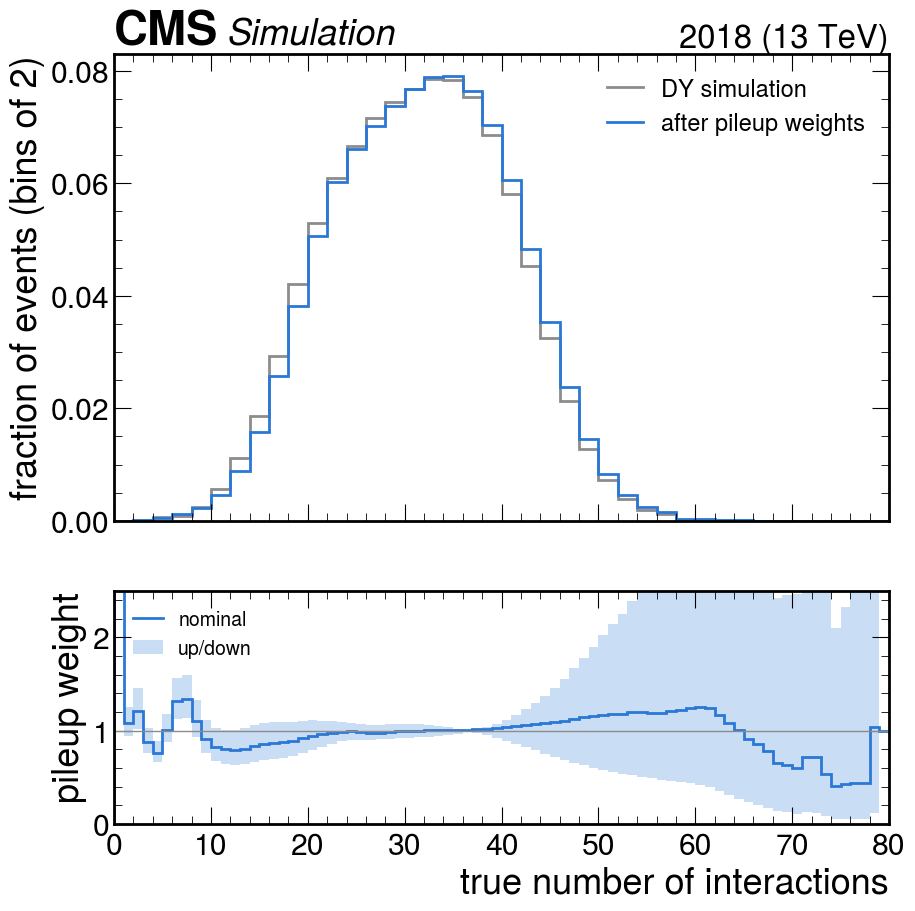

In [3]:
pu = corr.correction(corr.entry("pileup")["file"], corr.entry("pileup")["correction"])
n = np.arange(0, 100) + 0.5
h_w = {}
for key in ("nominal", "up", "down"):
    h_w[key] = hist.Hist(hist.axis.Regular(100, 0, 100, name="nTrueInt", label="true number of interactions"))
    h_w[key].view()[:] = pu.evaluate(n, key)

# In bins of two interactions: the campaign filled nTrueInt, an integer, into bins of
# width one whose edges sit on the integers, where floating-point rounding puts 29, 57 and
# 58 one bin low. Pairs keep 28 and 29 together; the only effect left is at 58, where the
# fraction of events is ~1e-3. (hists.py now centres the bins on the integers.)
pairs = hist.rebin(2)
before = study.fractions(hists(DY, "pileup_nTrueInt", ZCR, "uncorrected")[pairs])
after = study.fractions(hists(DY, "pileup_nTrueInt", ZCR, "only_pileup")[pairs])

fig, (ax, rax) = plt.subplots(2, 1, figsize=(10, 10), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
hep.histplot(before, ax=ax, color=GRAY, lw=2, yerr=False, label="DY simulation", flow="none")
hep.histplot(after, ax=ax, color=BLUE, lw=2, yerr=False, label="after pileup weights", flow="none")
ax.set_xlabel("")
ax.set_ylabel("fraction of events (bins of 2)")
ax.legend(fontsize=17)
hep.histplot(h_w["nominal"], ax=rax, color=BLUE, lw=2, yerr=False, label="nominal", flow="none")
study.band(rax, h_w["up"], h_w["down"], BLUE, label="up/down")
rax.axhline(1, color=GRAY, lw=1)
rax.set_ylim(0, 2.5)
rax.set_xlim(0, 80)
rax.set_ylabel("pileup weight")
rax.legend(fontsize=14, loc="upper left")
study.cms_label(ax)
study.save(fig, "standard_pileup_weights")
plt.show()

### What the weights do to a reconstructed quantity

The number of good reconstructed primary vertices follows the true number of
interactions. The band is the $\pm$4.6% cross-section variation.

The standard validation of the reweighting is this distribution in data against
simulation, in a region dominated by one well-modelled process. It is deliberately
not done here, since the analysis is blinded; it is listed in the README for the
group to decide where and when to look.

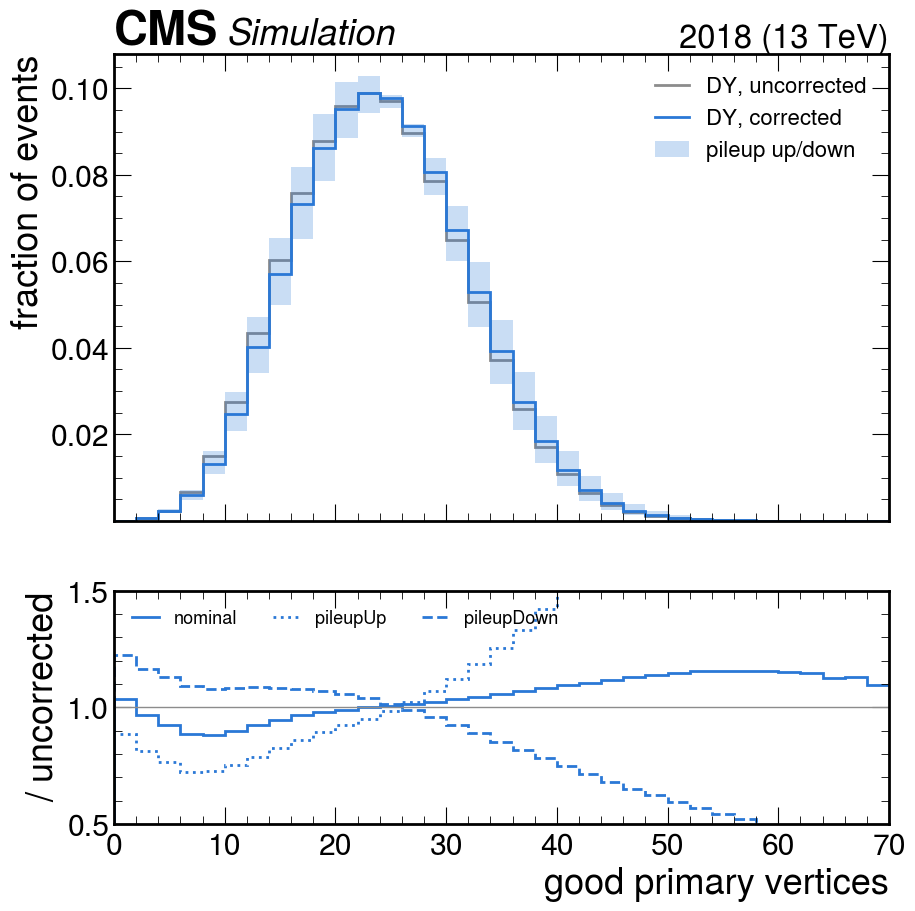

mean number of good vertices, DY uncorrected : 24.04
mean number of good vertices, DY nominal     : 24.38
mean number of good vertices, DY pileupUp    : 25.41
mean number of good vertices, DY pileupDown  : 23.36


In [4]:
rebin = hist.rebin(2)
mc = {c: study.fractions(hists(DY, "pv_npvsGood", ZCR, c)[rebin])
      for c in ("uncorrected", "nominal", "pileupUp", "pileupDown")}
axis = mc["nominal"].axes[0]

fig, (ax, rax) = plt.subplots(2, 1, figsize=(10, 10), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
hep.histplot(mc["uncorrected"], ax=ax, color=GRAY, lw=2, yerr=False, label="DY, uncorrected", flow="none")
hep.histplot(mc["nominal"], ax=ax, color=BLUE, lw=2, yerr=False, label="DY, corrected", flow="none")
study.band(ax, mc["pileupUp"], mc["pileupDown"], BLUE, label="pileup up/down")
ax.set_xlabel("")
ax.set_ylabel("fraction of events")
ax.legend(fontsize=16)
for label, ls in [("nominal", "-"), ("pileupUp", ":"), ("pileupDown", "--")]:
    ratio = hist.Hist(axis)
    num, den = mc[label].values(), mc["uncorrected"].values()
    ratio.view()[:] = np.divide(num, den, out=np.full_like(num, np.nan), where=den > 0)
    hep.histplot(ratio, ax=rax, color=BLUE, lw=2, ls=ls, yerr=False, label=label, flow="none")
rax.axhline(1, color=GRAY, lw=1)
rax.set_ylim(0.5, 1.5)
rax.set_xlim(0, 70)
rax.set_ylabel("/ uncorrected")
rax.legend(fontsize=13, ncol=3, loc="upper left")
study.cms_label(ax)
study.save(fig, "standard_pileup_vertices")
plt.show()

for label, h in mc.items():
    print(f"mean number of good vertices, DY {label:12s}: {study.binned_mean(h):.2f}")

### Effect on the normalisation

The yields are normalised with the plain genWeight sum, so a pileup weight whose
average over the sample is not exactly one changes the total. The processor records
the sums with each event correction, before any selection
(`metadata["scaled_sum_weights_corrected"]`):

In [5]:
def sum_shift(sample, name):
    meta = out[sample]["metadata"]
    return meta["scaled_sum_weights_corrected"][name] / meta["scaled_sum_weights"] - 1

print(f"{'sample':28s} {'pileup':>9s} {'prefiring':>10s} {'both':>9s}   (sum with correction / plain sum - 1)")
for s in [REP["2Mu2E"], REP["4Mu"], DY]:
    print(f"{s:28s} {100 * sum_shift(s, 'pileup'):+8.2f}% {100 * sum_shift(s, 'l1_prefiring'):+9.2f}% "
          f"{100 * sum_shift(s, 'all_event_level'):+8.2f}%")
for fs in study.FINAL_STATES:
    pts = [s for s in SIGNALS if s.startswith(fs + "_")]
    v = [100 * sum_shift(s, "pileup") for s in pts]
    print(f"all {fs} points: pileup changes the sum of weights by {min(v):+.2f} to {max(v):+.2f}%")

sample                          pileup  prefiring      both   (sum with correction / plain sum - 1)
2Mu2E_500GeV_1p2GeV_1p9mm       +0.02%     -0.39%    -0.36%
4Mu_500GeV_1p2GeV_1p9mm         +0.02%     -0.77%    -0.74%
DYJetsToMuMu_M50                -0.03%     -0.53%    -0.56%
all 2Mu2E points: pileup changes the sum of weights by -0.08 to +0.08%
all 4Mu points: pileup changes the sum of weights by -0.02 to +0.06%


For the skimmed DY sample the sums are over the skimmed events (divided by the skim
efficiency), so they measure the average weight of the events that entered the skim,
not of the whole sample.

## 2. L1 prefiring

In 2016 and 2017 the ECAL trigger primitives in the forward region were sometimes
assigned to the previous bunch crossing, and in all Run 2 years the same happened for
some L1 muon candidates. The event is then lost, because the L1 trigger rule vetoes
two consecutive crossings. NanoAOD carries the probability that an event survives,
computed from the offline muons (and photons and jets for the ECAL part). For 2018
the ECAL part is one, so only muons contribute. The mean is the exact
`only_l1_prefiring` over `uncorrected` yield ratio from the cutflow.

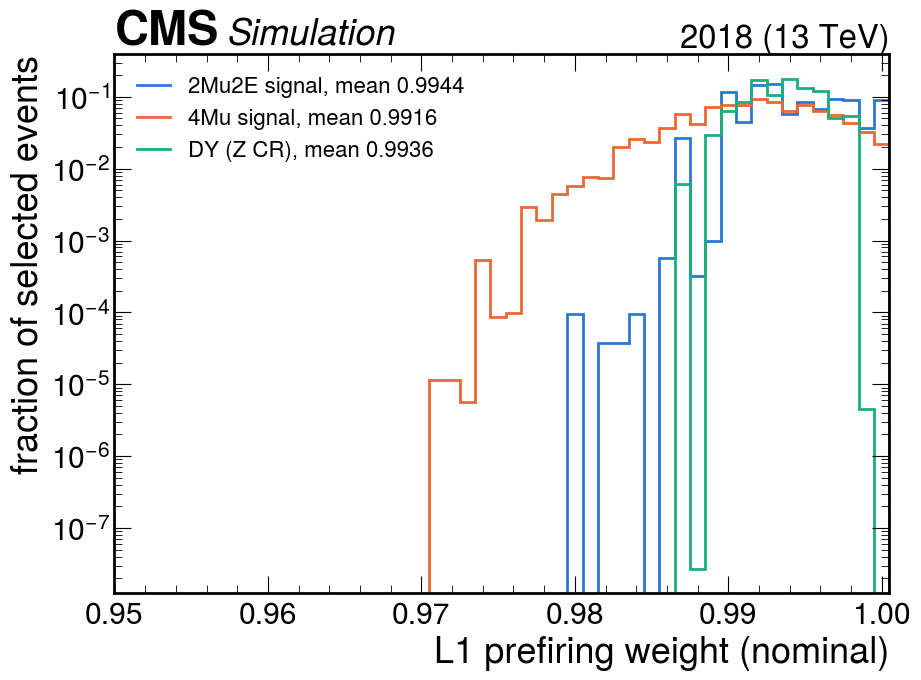

In [6]:
fig, ax = plt.subplots(figsize=(10, 7))
for sample, channel, color, label in [(REP["2Mu2E"], "base", BLUE, "2Mu2E signal"),
                                      (REP["4Mu"], "base", ORANGE, "4Mu signal"),
                                      (DY, ZCR, AQUA, "DY (Z CR)")]:
    y = study.yields(out[sample], channel)
    mean = y["only_l1_prefiring"] / y["uncorrected"]
    h = hists(sample, "weight_l1_prefiring", channel, "uncorrected")
    hep.histplot(study.fractions(h), ax=ax, color=color, lw=2, yerr=False,
                 label=f"{label}, mean {mean:.4f}", flow="sum")
ax.set_yscale("log")
ax.set_xlim(0.95, 1.0005)
ax.set_xlabel("L1 prefiring weight (nominal)")
ax.set_ylabel("fraction of selected events")
ax.legend(fontsize=16, loc="upper left")
study.cms_label(ax)
study.save(fig, "standard_prefiring")
plt.show()

The weight is a product over the muons of the event, so 4Mu loses the most: 0.84% of
the selected events on average, against 0.56% for 2Mu2E and 0.64% for DY, which have
two muons each. The weight is computed for PF muons only: a lepton jet made of DSA
muons alone does not enter it (see notebook 02).

## 3. Object scale factors for the lepton-jet constituents

Object SFs are evaluated for the constituents of the selected lepton jets, the
objects the event selection is built from, and multiplied per event. Which SF applies
is decided by the cuts of the channel: the muon ID SF is the Loose one because the
lepton-jet selection asks for `looseID`, and it would switch to the Tight one in a
channel that asks for `tightID` (as the $t\bar{t}$ control region does). The
histograms `lj_<object>_<correction>_sf` hold the SF of every constituent, at the
working point the channel uses.

object SFs used per channel: {'base': ['electron_reco:always', 'muon_id:looseID', 'photon_pixel_veto:pixelSeed'], '4mu': ['electron_reco:always', 'muon_id:looseID', 'photon_pixel_veto:pixelSeed'], 'Z_to_mumu_control_region': ['electron_reco:always', 'muon_id:looseID', 'photon_pixel_veto:pixelSeed']}
2Mu2E_500GeV_1p2GeV_1p9mm: 0.4% of the lepton-jet PF muons below 20 GeV (J/psi-based SFs), mean SF 0.9994
4Mu_500GeV_1p2GeV_1p9mm: 11.8% of the lepton-jet PF muons below 20 GeV (J/psi-based SFs), mean SF 0.9989


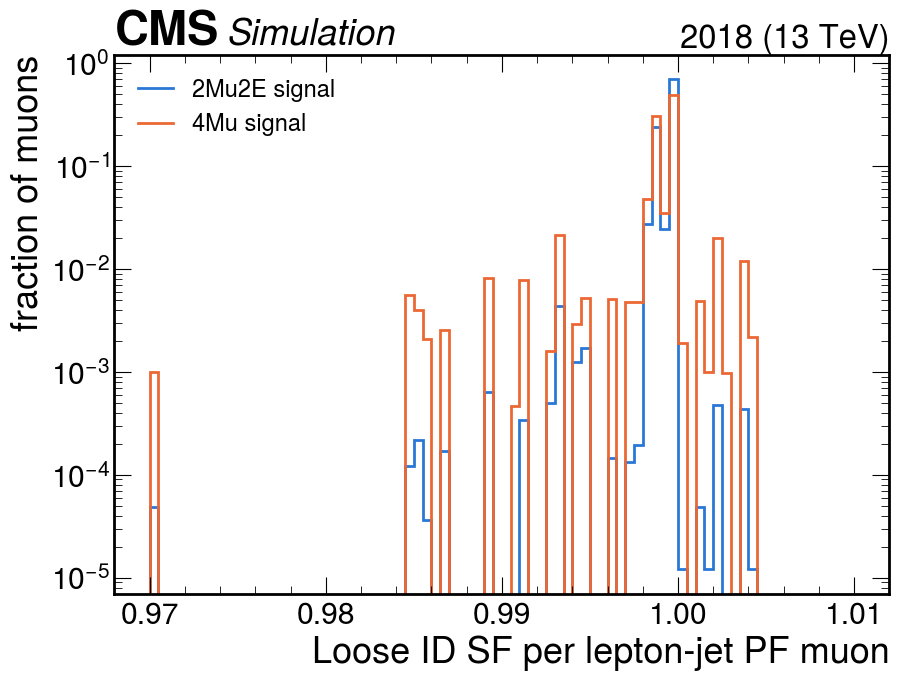

In [7]:
print("object SFs used per channel:",
      {c: sorted(v) for c, v in out[REP["2Mu2E"]]["metadata"]["object_corrections"].items() if c in ("base", "4mu", ZCR)})

fig, ax = plt.subplots(figsize=(10, 7))
for fs, color in [("2Mu2E", BLUE), ("4Mu", ORANGE)]:
    h2 = hists(REP[fs], "lj_pfMuon_muon_id_sf", study.CATEGORY[fs], "uncorrected")
    pt = h2.project("pt").values(flow=True)
    sf = h2.project("sf")
    below_20 = pt[:4].sum() / pt.sum()   # underflow and the 5-10, 10-15, 15-20 GeV bins
    print(f"{REP[fs]}: {100 * below_20:.1f}% of the lepton-jet PF muons below 20 GeV (J/psi-based SFs), "
          f"mean SF {study.binned_mean(sf):.4f}")
    hep.histplot(study.fractions(sf), ax=ax, color=color, lw=2, yerr=False, label=f"{fs} signal", flow="sum")
ax.set_yscale("log")
ax.set_xlabel("Loose ID SF per lepton-jet PF muon")
ax.set_ylabel("fraction of muons")
ax.legend(fontsize=17, loc="upper left")
study.cms_label(ax)
study.save(fig, "standard_muon_sf")
plt.show()

The electron reconstruction SF, evaluated at the supercluster $\eta$, and the photon
pixel-veto SF. The latter is shown to make its size visible; it is not in the default
list, for the reason given in notebook 02.

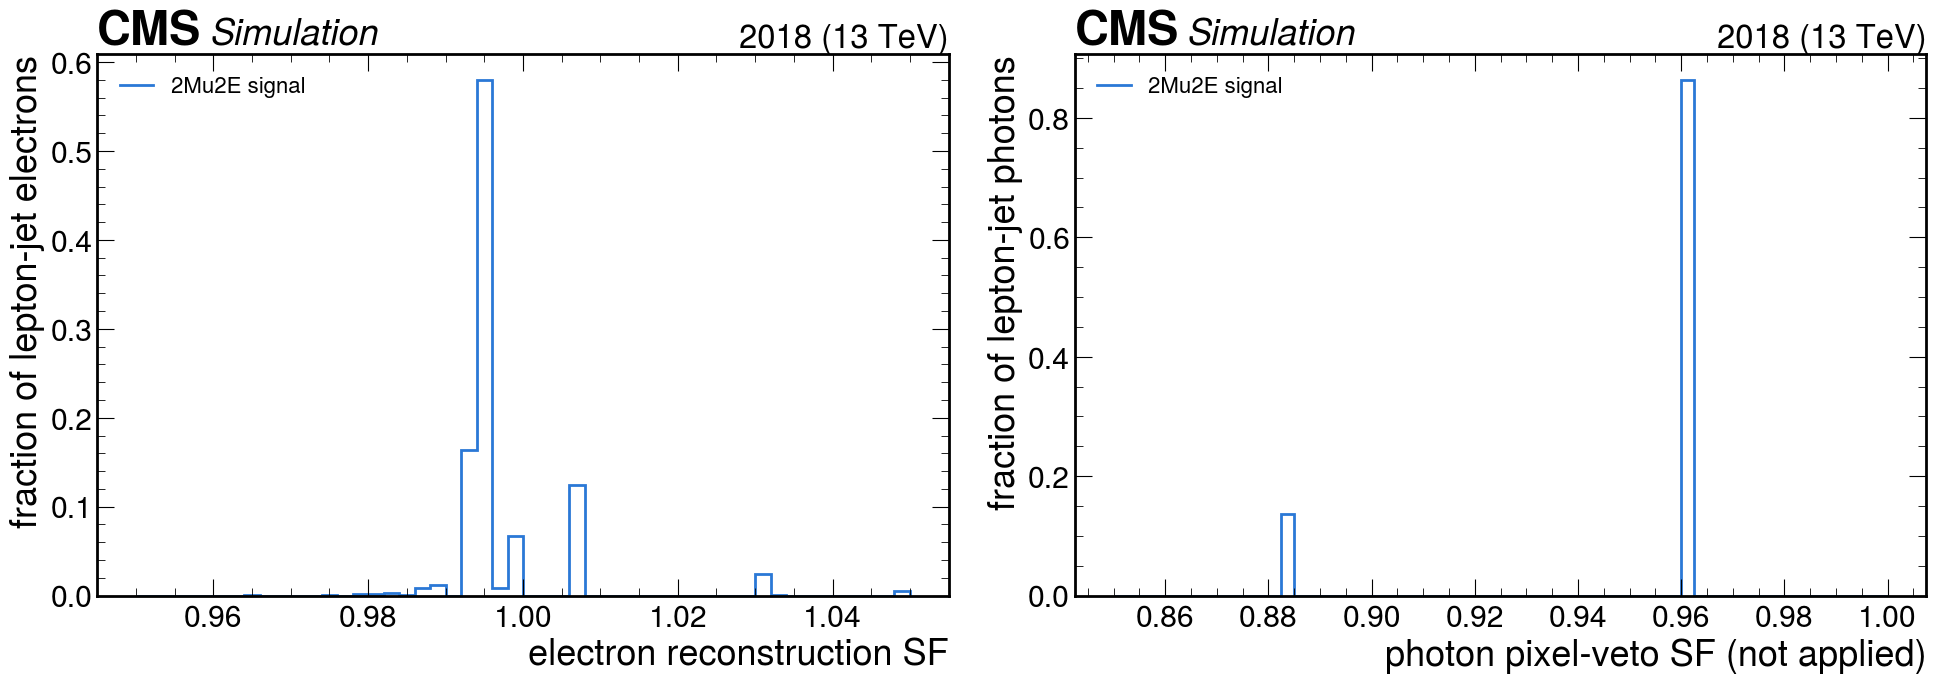

electrons: mean reco SF 0.9971, 0.7% below 20 GeV
photons: mean pixel-veto SF 0.9507 (barrel 0.961, endcap 0.884); 86% of the photons in the barrel


In [8]:
s, ch = REP["2Mu2E"], "2mu2e"
el = hists(s, "lj_electron_electron_reco_sf", ch, "uncorrected")
ph = hists(s, "lj_photon_photon_pixel_veto_sf", ch, "uncorrected")
el_sf, ph_sf = el.project("sf"), ph.project("sf")

fig, axs = plt.subplots(1, 2, figsize=(20, 7))
hep.histplot(study.fractions(el_sf), ax=axs[0], color=BLUE, lw=2, yerr=False, label="2Mu2E signal", flow="sum")
axs[0].set_ylabel("fraction of lepton-jet electrons")
hep.histplot(study.fractions(ph_sf), ax=axs[1], color=BLUE, lw=2, yerr=False, label="2Mu2E signal", flow="sum")
axs[1].set_xlabel("photon pixel-veto SF (not applied)")
axs[1].set_ylabel("fraction of lepton-jet photons")
for a in axs:
    a.legend(fontsize=16, loc="upper left")
plt.tight_layout()
study.cms_label(axs)
study.save(fig, "standard_egamma_sf")
plt.show()

el_pt = el.project("pt").values(flow=True)
print(f"electrons: mean reco SF {study.binned_mean(el_sf):.4f}, {100 * el_pt[:3].sum() / el_pt.sum():.1f}% below 20 GeV")
print(f"photons: mean pixel-veto SF {study.binned_mean(ph_sf):.4f} (barrel {study.binned_mean(ph[{'barrel': True}]):.3f}, "
      f"endcap {study.binned_mean(ph[{'barrel': False}]):.3f}); "
      f"{100 * ph[{'barrel': True}].sum().value / ph.sum().value:.0f}% of the photons in the barrel")

## 4. What the corrections do to the selected events

The event weight is the product of all factors. For the selected events of the two
benchmark points, the average of each factor (the `only_<name>` over `uncorrected`
yield) and the relative change of the yield under each variation, read from the
cutflow:

In [9]:
NAMES = corr.names
for fs in study.FINAL_STATES:
    s, ch = REP[fs], study.CATEGORY[fs]
    y = study.yields(out[s], ch)
    print(f"{s} ({ch}): corrected/uncorrected yield = {y['nominal'] / y['uncorrected']:.4f}")
    for name in NAMES:
        mean = y[f"only_{name}"] / y["uncorrected"]
        up, down = y[f"{name}Up"] / y["nominal"] - 1, y[f"{name}Down"] / y["nominal"] - 1
        print(f"    {name:16s} mean factor {mean:.4f}   up {100 * up:+6.2f}%   down {100 * down:+6.2f}%")
    w = y["with_photon_pixel_veto"] / y["nominal"]
    print(f"    {'photon_pixel_veto':16s} mean factor {w:.4f}   (monitored, not applied)")

2Mu2E_500GeV_1p2GeV_1p9mm (2mu2e): corrected/uncorrected yield = 0.9921
    pileup           mean factor 0.9995   up  -0.23%   down  +0.18%
    l1_prefiring     mean factor 0.9944   up  -0.13%   down  +0.13%
    muon_id          mean factor 0.9988   up  +0.03%   down  -0.03%
    electron_reco    mean factor 0.9993   up  +0.27%   down  -0.27%
    photon_pixel_veto mean factor 0.9688   (monitored, not applied)
4Mu_500GeV_1p2GeV_1p9mm (4mu): corrected/uncorrected yield = 0.9867
    pileup           mean factor 1.0000   up  +0.01%   down  +0.01%
    l1_prefiring     mean factor 0.9907   up  -0.23%   down  +0.23%
    muon_id          mean factor 0.9960   up  +0.48%   down  -0.48%
    electron_reco    mean factor 1.0000   up  +0.00%   down  -0.00%
    photon_pixel_veto mean factor 0.9993   (monitored, not applied)


## 5. Corrections already in NanoAODv9

Two families of corrections are applied when the NanoAOD is produced. Applying them
again would double count them.

* **Jet energy corrections.** NanoAODv9 jets carry `Summer19UL18_V5`, the current
  2018 UL tag; `00_correctionlib_tutorial.ipynb` recomputes the JEC from the raw jet
  $p_T$ and finds agreement within NanoAOD's float precision. The JES uncertainty and
  the JER smearing, which NanoAOD does *not* apply, are available as
  `Corrections.jes_uncertainty` and `Corrections.jer_smearing_factor`; notebook 02
  explains why they are not applied yet.
* **Electron and photon energy scale and smearing.** In UL NanoAOD the electron and
  photon energies already include the EGM corrections: the data scale and, in
  simulation, the smearing. `eCorr` is the ratio of the corrected to the uncorrected
  energy. In simulation it is not one, which is how we know the smearing is in. Here
  for the lepton-jet electrons and photons of every 2Mu2E point:

lepton-jet electrons: eCorr mean 1.0090, RMS 0.0556
lepton-jet photons: eCorr mean 1.0001, RMS 0.0138


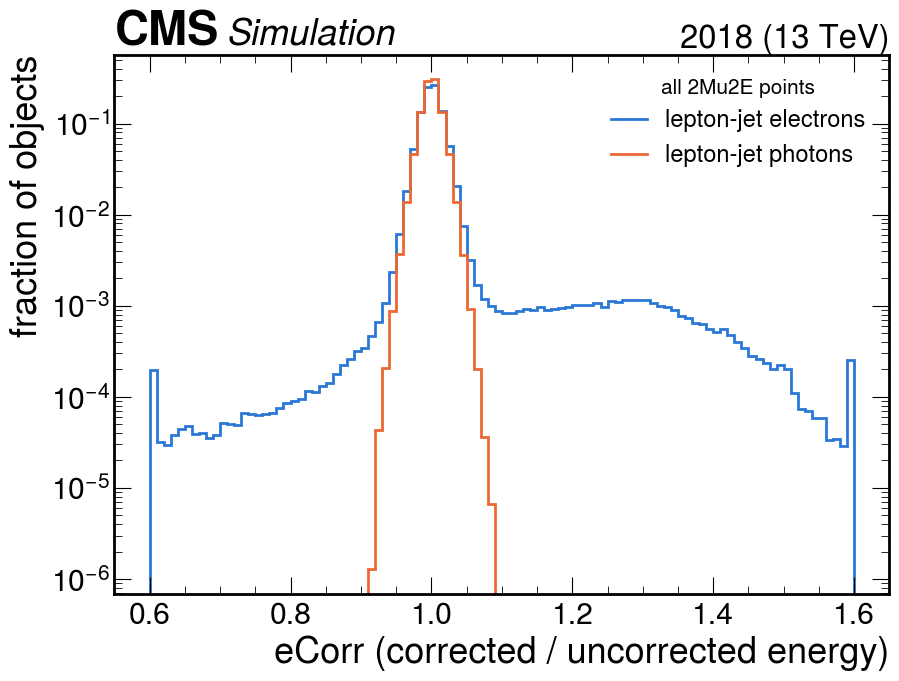

  lepton-jet electron dEscaleUp    non-zero for   0.0% of objects
  lepton-jet electron dEscaleDown  non-zero for   0.0% of objects
  lepton-jet electron dEsigmaUp    non-zero for  98.5% of objects
  lepton-jet electron dEsigmaDown  non-zero for  98.5% of objects
  lepton-jet photon   dEscaleUp    non-zero for   0.0% of objects
  lepton-jet photon   dEscaleDown  non-zero for   0.0% of objects
  lepton-jet photon   dEsigmaUp    non-zero for  98.5% of objects
  lepton-jet photon   dEsigmaDown  non-zero for  98.5% of objects


In [10]:
two_mu_two_e = [s for s in SIGNALS if s.startswith("2Mu2E_")]
def summed(name, channel="base", syst="uncorrected"):
    return sum(hists(s, name, channel, syst) for s in two_mu_two_e)

fig, ax = plt.subplots(figsize=(10, 7))
for name, color, label in [("lj_electron_eCorr", BLUE, "lepton-jet electrons"), ("lj_photon_eCorr", ORANGE, "lepton-jet photons")]:
    h = summed(name)
    hep.histplot(study.fractions(h), ax=ax, color=color, lw=2, yerr=False, label=label, flow="sum")
    mean = study.binned_mean(h)
    rms = np.sqrt(np.sum((h.axes[0].centers - mean) ** 2 * h.values()) / h.values().sum())
    print(f"{label}: eCorr mean {mean:.4f}, RMS {rms:.4f}")
ax.set_yscale("log")
ax.set_xlabel("eCorr (corrected / uncorrected energy)")
ax.set_ylabel("fraction of objects")
ax.legend(fontsize=17, title="all 2Mu2E points", title_fontsize=15)
study.cms_label(ax)
study.save(fig, "standard_ecorr")
plt.show()

for obj in ("electron", "photon"):
    v = summed(f"lj_{obj}_energy_variations").values()     # [variation, nonzero]
    for i, name in enumerate(["dEscaleUp", "dEscaleDown", "dEsigmaUp", "dEsigmaDown"]):
        print(f"  lepton-jet {obj:8s} {name:12s} non-zero for {100 * v[i, 1] / v[i].sum():5.1f}% of objects")

For the lepton-jet electrons `eCorr` has a mean of 1.009 and an RMS of 0.056, for the
photons 1.000 and 0.014: the smearing is in. NanoAOD also stores the energy variations
for a later shape systematic, but in these ntuples only half of them are usable: the
smearing variations (`dEsigmaUp/Down`) are filled for 98.5% of the objects, while the
**energy-scale variations (`dEscaleUp/Down`) are zero for every electron and photon in
simulation**. The scale uncertainty for simulation therefore has to come from
elsewhere; it is listed as an open item in the README. Muon momentum (Rochester)
corrections are *not* in NanoAOD, and for Run 2 they are not distributed as a
correctionlib file; they are small for muons of our momenta and are listed as an open
item in the README.

## Summary

| correction | applied | check in this notebook |
|---|---|---|
| pileup | yes | the UL18 simulated profile is already close to the 2018 target: the weights change the sums of weights by less than 0.1% for every signal point and DY; data/MC vertex check left open (blinded) |
| L1 prefiring | yes | a few tenths of a percent per muon: 0.56% (2Mu2E), 0.84% (4Mu), 0.64% (DY) of the selected events |
| PF muon Loose ID | yes | SF within 1–2% of one; J/psi-based below 20 GeV (0.4% of the 2Mu2E and 12% of the 4Mu benchmark muons), Z-based above |
| electron reconstruction | yes | mean SF 0.997 for lepton-jet electrons |
| photon pixel veto | monitored, not applied | 0.96 barrel, 0.88 endcap per photon; would lower the 2Mu2E benchmark by 3.1%; see notebook 02 |
| JEC | already in NanoAOD | recomputed in notebook 00 |
| EGM scale and smearing | already in NanoAOD | `eCorr` differs from one in simulation; scale variations are empty in these ntuples |
| JER smearing, JES uncertainty | no | tools provided; see notebook 02 |

The `DYJetsToMuMu_M50` skim contains one event with a generator weight of 1.45e14,
which alone is 99.8% of the sample's sum of weights. `study.load` takes it out of the
normalisation (`corrections_study.GENWEIGHT_OUTLIERS`); see the README.